# Analyzing Georgia data

This article puts two datasets side by side: infant mortality from the
Georgia Department of Public Health and the poverty rate from the U.S.
Census. Infant mortality, the number of babies who die before their first
birthday per 1,000 live births, is one of the most widely used measures of a
community's health. The article shows the steps any such analysis needs.

In [1]:
import warnings

import pandas as pd

warnings.formatwarning = lambda message, category, *args, **kwargs: (
    f"{category.__name__}: {message}\n"
)
pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 10)
pd.set_option("display.max_colwidth", 45)

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

import georgiacivicdata as gcd

## Pick the datasets

In [3]:
gcd.search("infant mortality", n=3)[["name", "title", "year_min", "year_max"]]

,name,title,year_min,year_max
0,infant_deaths,Infant Deaths and Infant Mortality Rates,2000,2025
1,fetal_deaths,Fetal Deaths and Fetal Mortality Rates,2000,2025
2,birth_outcomes,Birth Outcomes (Low Birthweight and Prete...,2000,2025


In [4]:
gcd.search("poverty rate", level="counties", n=3)[["name", "title", "year_min", "year_max"]]

,name,title,year_min,year_max
0,poverty,Poverty (ACS),2020,2024
1,poverty_by_nativity,Poverty by Nativity and Citizenship (ACS),2020,2024
2,low_income_low_access_tracts,"Low-Income, Low-Access Tracts (USDA 2025 ...",2025,2025


`infant_deaths` holds infant deaths and live births from the state's OASIS
system, by county of residence; `poverty` is the American Community Survey
(ACS) 5-year estimate of the share of people below the federal poverty line.
Before joining them, check that they share a detail level and a key, and
which years they cover:

In [5]:
infant_info = gcd.describe("infant_deaths")
poverty_info = gcd.describe("poverty")

print(
    "Shared detail levels:",
    sorted(set(infant_info.detail_levels) & set(poverty_info.detail_levels)),
)
print("Shared grain:", sorted(set(infant_info.grain) & set(poverty_info.grain)))
print("Infant deaths years:", min(infant_info.years), "-", max(infant_info.years))
print("Poverty years:", min(poverty_info.years), "-", max(poverty_info.years))

Shared detail levels: ['counties', 'states']
Shared grain: ['county_fips', 'tract_geoid', 'year']
Infant deaths years: 2000 - 2025
Poverty years: 2020 - 2024


Both publish county rows keyed by `county_fips`. The ACS figures are 5-year
estimates named by their end year, so the 2024 vintage pools survey
responses from 2020 to 2024. We match it with the infant deaths of 2020 to
2024.

## Read the notes first

The dataset's notes say which columns can't be added up. Causes and ages at
death nest inside each other (`all` contains every cause, and `neonatal`
contains `early_neonatal`), so summing across them counts the same deaths
more than once:

In [6]:
infant_info.notes["non_additive"]["column"].tolist()

['cause', 'age_at_death']

Pinning both to `all` gives one row per county, year and group. The notes
also set a floor on any figure we compute ourselves:

In [7]:
print(infant_info.notes["pooled_min_count"]["reason"].iloc[0])

OASIS withholds rates based on 1-4 deaths (shown as * on OASIS), so no figure combined from fewer than 5 deaths is given.


## Pool infant mortality from counts

`gcd.columns()` names the numerator and denominator of the rate:

In [8]:
cols = gcd.columns("infant_deaths")
cols.loc[cols["metric_component"].notna(), ["column", "metric_component"]]

,column,metric_component
11,num_deaths,numerator
12,num_births,denominator


In [9]:
infant = gcd.rows(
    "infant_deaths",
    detail="counties",
    demographic="all",
    cause="all",
    age_at_death="all",
    year=range(2020, 2025),
    quiet=True,
)

pd.DataFrame(
    {
        "county_years": [len(infant)],
        "with_a_rate": [infant["death_rate_per_1k_births"].notna().sum()],
        "median_births": [infant["num_births"].median()],
    }
)

,county_years,with_a_rate,median_births
0,795,385,258.0


Infant deaths are rare and most of Georgia's 159 counties are small. In a
typical county-year a few hundred babies are born and a single death moves
the rate by several points. That is why about half of the county-years have
no published rate at all. A county's rate over several years is the sum of
its deaths over the sum of its births, not the average of its yearly rates:

In [10]:
pooled = (
    infant.groupby(["county_fips", "county_name"], as_index=False)
    .agg(deaths=("num_deaths", "sum"), births=("num_births", "sum"))
    .assign(infant_mortality=lambda d: 1000 * d["deaths"] / d["births"])
)

pooled.sort_values("births", ascending=False).head()

,county_fips,county_name,deaths,births,infant_mortality
66,13135,Gwinnett,323,56843,5.682318
59,13121,Fulton,389,56491,6.886053
43,13089,DeKalb,299,49609,6.027132
32,13067,Cobb,229,43244,5.295532
30,13063,Clayton,177,19212,9.212992


In [11]:
few = int((pooled["deaths"] < 5).sum())
print(f"Counties with fewer than five infant deaths in 2020-2024: {few}")

Counties with fewer than five infant deaths in 2020-2024: 41


Even pooled over five years, those counties had too few infant deaths for a
rate under the dataset's own rule. We keep their counts for the group sums
below but leave them out of any county-level figure.

Pooling and averaging give different answers whenever counties differ in
size. Here is the comparison with the published state rows:

In [12]:
state = gcd.rows(
    "infant_deaths",
    detail="states",
    demographic="all",
    cause="all",
    age_at_death="all",
    year=range(2020, 2025),
    quiet=True,
)

pd.DataFrame(
    {
        "infant_mortality": [
            pooled["infant_mortality"].mean(),
            1000 * pooled["deaths"].sum() / pooled["births"].sum(),
            1000 * state["num_deaths"].sum() / state["num_births"].sum(),
        ],
        "births": pd.array(
            [None, pooled["births"].sum(), state["num_births"].sum()], dtype="Int64"
        ),
    },
    index=["mean of county rates", "pooled from county counts", "state rows"],
)

,infant_mortality,births
mean of county rates,6.939697,<NA>
pooled from county counts,6.651060,623660
state rows,6.651060,623660


The counties add up to the state row exactly, so the rate pooled from county
counts matches the state's. The plain mean of county rates is further off,
because it weighs a county with a hundred births like one with fifty
thousand.

## Join the poverty rate

In [13]:
poverty = gcd.rows(
    "poverty",
    detail="counties",
    year=2024,
    race_iteration="all",
    quiet=True,
)[["county_fips", "poverty_rate", "poverty_rate_moe"]]

joined = pooled.merge(poverty, on="county_fips", how="inner")
len(joined)

159

The ACS reports a 90% margin of error beside each estimate; for small
counties it can be a sizable share of the estimate:

In [14]:
moe_share = joined["poverty_rate_moe"] / joined["poverty_rate"]
pd.Series({"median_moe_share": moe_share.median(), "max_moe_share": moe_share.max()})

median_moe_share    0.190001
max_moe_share       0.507069
dtype: float64

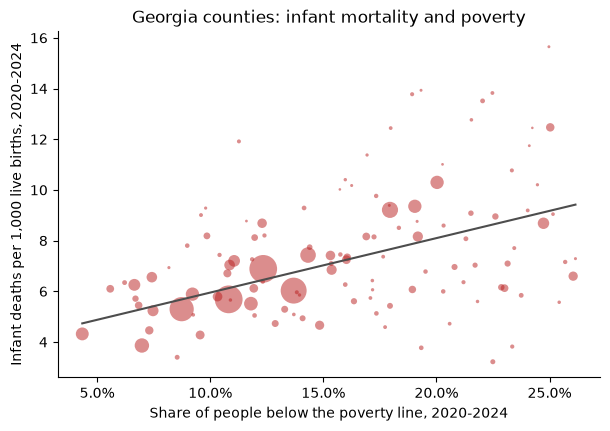

In [15]:
rated = joined[joined["deaths"] >= 5]

x = rated["poverty_rate"].to_numpy(dtype=float)
y = rated["infant_mortality"].to_numpy(dtype=float)
w = rated["births"].to_numpy(dtype=float)
slope, intercept = np.polyfit(x, y, 1, w=np.sqrt(w))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x, y, s=w / w.max() * 400, alpha=0.5, color="#b91c1c", edgecolor="none")
grid = np.linspace(x.min(), x.max(), 50)
ax.plot(grid, intercept + slope * grid, color="0.3")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Share of people below the poverty line, 2020-2024")
ax.set_ylabel("Infant deaths per 1,000 live births, 2020-2024")
ax.set_title("Georgia counties: infant mortality and poverty")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Each point is a county with at least five infant deaths in 2020-2024, sized
by its births; the line is a straight-line fit weighted by births.

In [16]:
# Spearman's rank correlation: the correlation of the ranks
round(float(rated["poverty_rate"].rank().corr(rated["infant_mortality"].rank())), 2)

0.37

County by county the association is modest, partly because even five-year
rates in small counties carry a lot of chance variation. Grouping counties
by their poverty rate and pooling each group's counts gives steadier rates.
Every county counts here, including those with too few deaths for a rate of
their own:

In [17]:
thirds = joined.assign(
    poverty_group=pd.qcut(
        joined["poverty_rate"], 3, labels=["Lowest third", "Middle third", "Highest third"]
    )
)

(
    thirds.groupby("poverty_group", observed=True)
    .agg(counties=("county_fips", "size"), deaths=("deaths", "sum"), births=("births", "sum"))
    .assign(infant_mortality=lambda d: 1000 * d["deaths"] / d["births"])
)

,counties,deaths,births,infant_mortality
poverty_group,,,,
Lowest third,53,2345,395522,5.928874
Middle third,53,1229,155432,7.906995
Highest third,53,574,72706,7.894809


Babies born in the middle and highest-poverty thirds of counties die before
their first birthday at a rate about a third higher than babies born in the
lowest-poverty third. The lowest-poverty third holds most of the state's
births, so it sets the state's rate.

## What these figures can't tell

- **Association, not causation.** Poverty is one of many ways counties
  differ; nothing here says a county's poverty rate causes infant deaths.
- **Counties are not families.** A county's poverty rate describes all of
  its residents, not the families of the babies born there.
- **Estimates carry error.** The ACS poverty rate is a survey estimate with
  a margin of error, larger in small counties; a county near a group
  boundary could sit in either.
- **Small counts swing.** A county's rate on a few deaths says little on its
  own; group and pool before comparing places.
- **Infant mortality has many causes.** The dataset's `cause` and
  `age_at_death` filters split deaths into prematurity, birth defects,
  sudden infant death and others, which this article does not look at.